EMPLOYEE TASK SCHEDULING RESULTS

(mu, lambda) Strategy Schedule:
  Task   Employee  Duration  Priority  Deadline Skill Match
Task 1 Employee 4         3         5         5         Yes
Task 2 Employee 2         4         4         8         Yes
Task 3 Employee 3         2         3         4         Yes
Task 4 Employee 3         5         5        10         Yes
Task 5 Employee 1         3         2         7         Yes
Task 6 Employee 5         4         4         9         Yes
Best Fitness: 47.6

(mu + lambda) Strategy Schedule:
  Task   Employee  Duration  Priority  Deadline Skill Match
Task 1 Employee 1         3         5         5         Yes
Task 2 Employee 5         4         4         8         Yes
Task 3 Employee 2         2         3         4         Yes
Task 4 Employee 3         5         5        10         Yes
Task 5 Employee 4         3         2         7         Yes
Task 6 Employee 2         4         4         9         Yes
Best Fitness: 47.2

COMPARISON OF BOTH ST

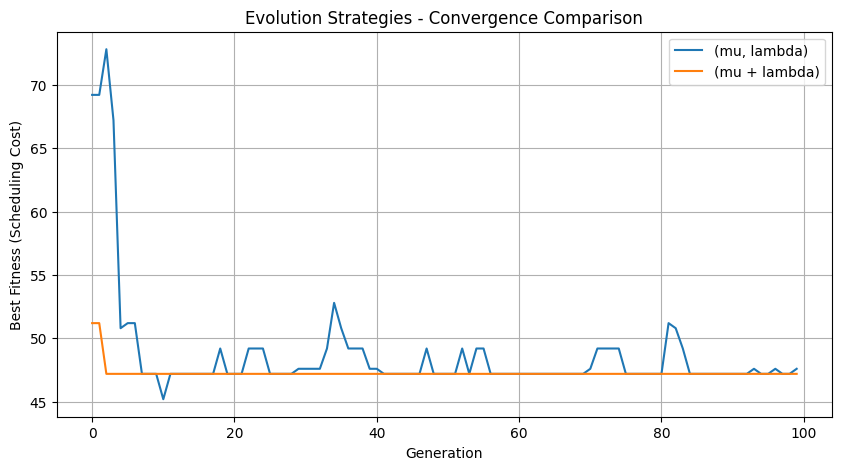


Assignment 4 Completed Successfully!


In [1]:

import numpy as np
import random
import time
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# ASSIGNMENT 4: EMPLOYEE TASK SCHEDULING
# USING EVOLUTION STRATEGIES
# ==========================================

random.seed(42)
np.random.seed(42)

# Problem Dataset
employees = [
    {"name": "Employee 1", "skills": [1, 1, 0, 0]},
    {"name": "Employee 2", "skills": [0, 1, 1, 0]},
    {"name": "Employee 3", "skills": [0, 0, 1, 1]},
    {"name": "Employee 4", "skills": [1, 0, 0, 1]},
    {"name": "Employee 5", "skills": [1, 1, 1, 0]}
]

tasks = [
    {"name": "Task 1", "duration": 3, "priority": 5, "deadline": 5, "skill": 0},
    {"name": "Task 2", "duration": 4, "priority": 4, "deadline": 8, "skill": 1},
    {"name": "Task 3", "duration": 2, "priority": 3, "deadline": 4, "skill": 2},
    {"name": "Task 4", "duration": 5, "priority": 5, "deadline": 10, "skill": 3},
    {"name": "Task 5", "duration": 3, "priority": 2, "deadline": 7, "skill": 0},
    {"name": "Task 6", "duration": 4, "priority": 4, "deadline": 9, "skill": 2}
]

# Evolution Strategy Parameters
MU = 20
LAMBDA = 40
GENERATIONS = 100
MUTATION_RATE = 0.2
MUTATION_STEP_SIZE = 1

NUM_TASKS = len(tasks)
NUM_EMPLOYEES = len(employees)

# Solution Representation:
# Each gene represents the employee assigned to a task.
# Example: [0, 2, 1, 3, 4, 2]

def create_individual():
    return np.random.randint(0, NUM_EMPLOYEES, NUM_TASKS)

# Fitness Function
def fitness(individual):
    total_cost = 0
    employee_workload = [0] * NUM_EMPLOYEES

    for i, employee_id in enumerate(individual):
        task = tasks[i]
        employee = employees[employee_id]

        employee_workload[employee_id] += task["duration"]

        # Skill mismatch penalty
        if employee["skills"][task["skill"]] == 0:
            total_cost += 20

        # Deadline penalty
        if task["duration"] > task["deadline"]:
            total_cost += 15

        # Priority-weighted task cost
        total_cost += task["duration"] * (6 - task["priority"])

    # Workload imbalance penalty
    avg_workload = np.mean(employee_workload)
    total_cost += sum(
        abs(load - avg_workload) for load in employee_workload
    )

    return total_cost

# Mutation Strategy
def mutate(individual):
    child = individual.copy()

    for i in range(NUM_TASKS):
        if random.random() < MUTATION_RATE:
            step = random.choice([-MUTATION_STEP_SIZE,
                                  MUTATION_STEP_SIZE])
            child[i] = (child[i] + step) % NUM_EMPLOYEES

    return child

# Generate initial population
def initialize_population():
    return [create_individual() for _ in range(MU)]

# Evolution Strategy: (mu, lambda)
def evolution_comma():
    population = initialize_population()
    history = []

    for generation in range(GENERATIONS):
        offspring = []

        for _ in range(LAMBDA):
            parent = random.choice(population)
            child = mutate(parent)
            offspring.append(child)

        population = sorted(offspring, key=fitness)[:MU]
        history.append(fitness(population[0]))

    return population[0], history

# Evolution Strategy: (mu + lambda)
def evolution_plus():
    population = initialize_population()
    history = []

    for generation in range(GENERATIONS):
        offspring = []

        for _ in range(LAMBDA):
            parent = random.choice(population)
            child = mutate(parent)
            offspring.append(child)

        combined = population + offspring
        population = sorted(combined, key=fitness)[:MU]
        history.append(fitness(population[0]))

    return population[0], history

# Run Both Strategies
start = time.time()
best_comma, history_comma = evolution_comma()
time_comma = time.time() - start

start = time.time()
best_plus, history_plus = evolution_plus()
time_plus = time.time() - start

# Display Results
def display_schedule(solution):
    result = []

    for i, employee_id in enumerate(solution):
        result.append({
            "Task": tasks[i]["name"],
            "Employee": employees[employee_id]["name"],
            "Duration": tasks[i]["duration"],
            "Priority": tasks[i]["priority"],
            "Deadline": tasks[i]["deadline"],
            "Skill Match": "Yes" if employees[employee_id]["skills"][tasks[i]["skill"]] else "No"
        })

    return pd.DataFrame(result)

print("=" * 55)
print("EMPLOYEE TASK SCHEDULING RESULTS")
print("=" * 55)

print("\n(mu, lambda) Strategy Schedule:")
print(display_schedule(best_comma).to_string(index=False))
print("Best Fitness:", fitness(best_comma))

print("\n(mu + lambda) Strategy Schedule:")
print(display_schedule(best_plus).to_string(index=False))
print("Best Fitness:", fitness(best_plus))

# Comparison Table
comparison = pd.DataFrame({
    "Measure": ["Best Fitness", "Mean Fitness", "Convergence", "Execution Time (seconds)"],
    "(mu, lambda)": [
        min(history_comma),
        np.mean(history_comma),
        next((i + 1 for i, x in enumerate(history_comma)
              if x <= min(history_comma) * 1.05),
             GENERATIONS),
        time_comma
    ],
    "(mu + lambda)": [
        min(history_plus),
        np.mean(history_plus),
        next((i + 1 for i, x in enumerate(history_plus)
              if x <= min(history_plus) * 1.05),
             GENERATIONS),
        time_plus
    ]
})

print("\nCOMPARISON OF BOTH STRATEGIES")
print(comparison.to_string(index=False))

# Convergence Graph
plt.figure(figsize=(10, 5))
plt.plot(history_comma, label="(mu, lambda)")
plt.plot(history_plus, label="(mu + lambda)")
plt.xlabel("Generation")
plt.ylabel("Best Fitness (Scheduling Cost)")
plt.title("Evolution Strategies - Convergence Comparison")
plt.legend()
plt.grid(True)
plt.show()

print("\nAssignment 4 Completed Successfully!")
